# Swiss transmission grid: power flow and OPF

This notebook builds the Swiss 220/380 kV grid from public data, fills it with one hour of measured load, production and cross-border exchange, and runs:

1. an AC power flow with the measured production,
2. a DC optimal power flow (OPF) that finds the cheapest Swiss dispatch within the line limits,
3. an AC power flow on the OPF result.

The first run downloads about 60 MB and takes about 2 minutes. Later runs read from `data/`.

In [1]:
import copy
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection

import data
import network

## 1. Build the grid

Lines and transformers come from OpenStreetMap (PyPSA-Eur). Every Swiss power plant from the federal register is connected to its nearest substation. Each foreign substation at the border gets one injection for the exchange with that country.

In [2]:
net = network.build()
pd.Series({
    "Swiss substations": (net.bus.zone == "CH").sum(),
    "border substations": (net.bus.zone != "CH").sum(),
    "lines": len(net.line),
    "transformers": len(net.trafo),
    "installed capacity GW": net.sgen.capacity_mw[net.sgen.type != "Border"].sum() / 1000,
}).round(1)

Swiss substations        186.0
border substations        24.0
lines                    253.0
transformers              34.0
installed capacity GW     25.7
dtype: float64

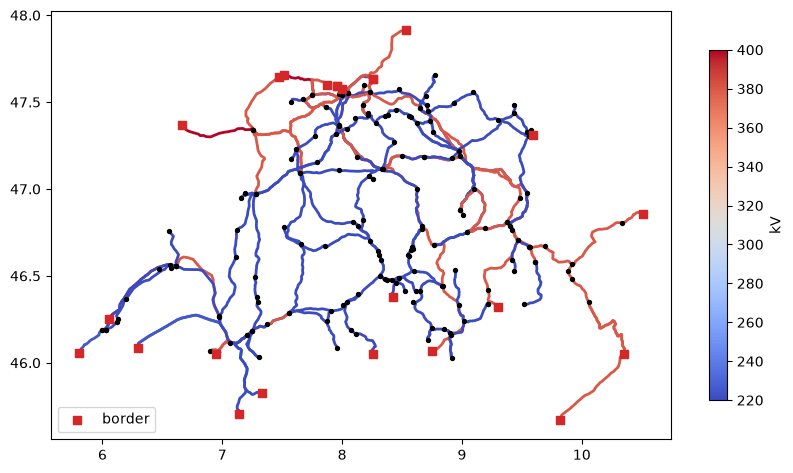

In [3]:
def draw(net, values, label, cmap="viridis"):
    fig, ax = plt.subplots(figsize=(10, 6.5))
    lines = ax.add_collection(LineCollection(net.line.coords, array=values, cmap=cmap, linewidths=2))
    border = net.bus.zone != "CH"
    ax.scatter(net.bus.lon[~border], net.bus.lat[~border], s=8, color="k", zorder=3)
    ax.scatter(net.bus.lon[border], net.bus.lat[border], s=40, marker="s", color="tab:red", zorder=3, label="border")
    ax.autoscale()
    ax.set_aspect(1.45)
    ax.legend(loc="lower left")
    fig.colorbar(lines, ax=ax, shrink=0.7, label=label)


draw(net, net.bus.vn_kv[net.line.from_bus].to_numpy(), "kV", cmap="coolwarm")

## 2. Pick an hour

- Load per canton and the exchange with each neighbour come from Swissgrid.
- Production per type comes from Energy-Charts, scaled to the Swissgrid total.
- Inside a canton the load is split equally over its substations. Inside a type, production is split by installed capacity.

In [4]:
YEAR = 2025
HOUR = pd.Timestamp("2025-01-15 18:00", tz="Europe/Zurich")

swissgrid = data.swissgrid(YEAR)
generation = data.generation(YEAR)
network.set_hour(net, swissgrid, generation, HOUR)

plants = net.sgen.type != "Border"
pd.Series({
    "load MW": net.load.p_mw.sum(),
    "production MW": net.sgen.p_mw[plants].sum(),
    "net import MW": net.sgen.p_mw[~plants].sum(),
}).round(0)

load MW           9677.0
production MW    12253.0
net import MW    -2570.0
dtype: float64

## 3. AC power flow

Newton-Raphson with the measured production. The slack is one border substation; it covers the losses and the small gap in the data.

In [5]:
network.run_power_flow(net)
power_flow = network.summary(net)
power_flow

production MW  Hydro run-of-river    1833.0
               Hydro storage         7098.0
               Nuclear               2853.0
               Others                 438.0
               Solar                    0.0
               Wind                    30.0
import MW      AT                    -910.0
               DE                   -2287.0
               FR                    -206.0
               IT                     832.0
               slack                   98.0
Name: p_mw, dtype: float64

In [6]:
lines = net.line[["name"]].assign(loading_percent=net.res_line.loading_percent, p_mw=net.res_line.p_from_mw)
print(f"voltage {net.res_bus.vm_pu.min():.3f} to {net.res_bus.vm_pu.max():.3f} pu, losses {net.res_line.pl_mw.sum():.0f} MW")
lines.sort_values("loading_percent", ascending=False).head(10).round(1)

voltage 0.920 to 1.051 pu, losses 102 MW


,name,loading_percent,p_mw
8,merged_relation/5978223:a-220+1,64.8,-316.1
248,way/927740824-220,50.4,241.2
243,way/76706345-220,50.1,-252.5
2,merged_relation/14096018:b-380+5,50.0,-787.8
94,relation/5435444:b-220,46.7,-229.9
93,relation/5435443:b-220,46.7,-229.9
95,relation/5462443-220,45.2,-201.4
100,relation/5552980-220,44.0,-208.6
115,relation/5645841-220,41.5,-197.0
73,merged_way/720907970:b-220+2,41.2,198.0


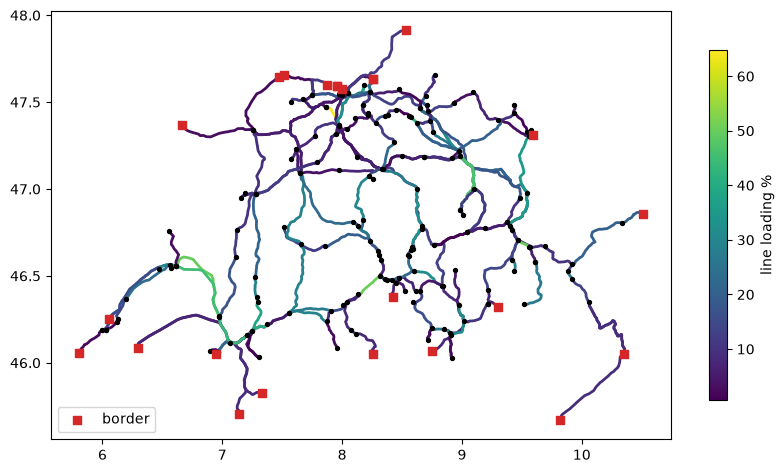

In [7]:
draw(net, net.res_line.loading_percent.to_numpy(), "line loading %")

## 4. DC optimal power flow

The OPF keeps the load and the exchange with each neighbour. It chooses which Swiss plants produce, at the lowest cost, without any line or transformer above 100 %.

- Nuclear and storage hydro can produce up to their installed capacity.
- Run-of-river, solar, wind and others can produce up to what they produced in this hour.
- Costs per MWh are in `network.COST`.

In [8]:
network.COST

{'Solar': 0.0,
 'Wind': 0.0,
 'Hydro run-of-river': 1.0,
 'Nuclear': 5.0,
 'Hydro storage': 30.0,
 'Others': 60.0}

In [9]:
opf = network.run_opf(copy.deepcopy(net))
dc_result = network.summary(opf)
print(f"highest line loading {opf.res_line.loading_percent.max():.1f} %")

highest line loading 68.7 %


Check the OPF dispatch with an AC power flow:

In [10]:
network.run_power_flow(opf)
pd.DataFrame({"measured, AC": power_flow, "OPF, DC": dc_result, "OPF, AC check": network.summary(opf)})

measured, AC  OPF, DC  OPF, AC check
production MW Hydro run-of-river        1833.0   1833.0         1833.0
              Hydro storage             7098.0   7367.0         7367.0
              Nuclear                   2853.0   3015.0         3015.0
              Others                     438.0      0.0            0.0
              Solar                        0.0      0.0            0.0
              Wind                        30.0     30.0           30.0
import MW     AT                        -910.0   -910.0         -910.0
              DE                       -2287.0  -2287.0        -2287.0
              FR                        -206.0   -206.0         -206.0
              IT                         832.0    832.0          832.0
              slack                       98.0      2.0          113.0

## 5. Try a weaker grid

Lower the line limit to 60 % and run the OPF again. To keep every line below the limit, the OPF must move production to other substations.

In [11]:
weak = copy.deepcopy(net)
weak.line["max_loading_percent"] = 60
network.run_opf(weak)
moved = (weak.sgen.p_mw - opf.sgen.p_mw).abs().sum() / 2
print(f"highest line loading {weak.res_line.loading_percent.max():.1f} %, {moved:.0f} MW moved between substations")
pd.DataFrame({"limit 100 %": dc_result, "limit 60 %": network.summary(weak)})

highest line loading 60.0 %, 1392 MW moved between substations


limit 100 %  limit 60 %
production MW Hydro run-of-river       1833.0      1833.0
              Hydro storage            7367.0      7367.0
              Nuclear                  3015.0      2978.0
              Others                      0.0        36.0
              Solar                       0.0         0.0
              Wind                       30.0        30.0
import MW     AT                       -910.0      -910.0
              DE                      -2287.0     -2287.0
              FR                       -206.0      -206.0
              IT                        832.0       832.0
              slack                       2.0         2.0

If the OPF raises `OPFNotConverged`, no dispatch can meet the limits with the measured exchange (for example at 40 %).